Analisis de datos

In [21]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
from arch import arch_model

In [22]:
ROOT = Path.cwd()

while not (ROOT / "Data").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("No encontré la carpeta Data subiendo desde el directorio actual.")
    ROOT = ROOT.parent

RETURNS_PATH = ROOT / "Data" / "returns.csv"

returns = pd.read_csv(RETURNS_PATH, index_col=0, parse_dates=True)
returns.columns = returns.columns.astype(str).str.strip()

print("ROOT:", ROOT)
print("Shape:", returns.shape)
print("Total tickers:", len(returns.columns))
returns.head()

ROOT: c:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz
Shape: (2061, 40)
Total tickers: 40


,AAPL,ALUA.BA,AMZN,BBAR.BA,BMA.BA,BRK-B,CEPU.BA,COME.BA,EDN.BA,EEM,...,TGSU2.BA,TLT,TSLA,TXAR.BA,UNH,V,VALO.BA,VNQ,XOM,YPFD.BA
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-03,-0.000174,0.052547,0.012694,0.006173,0.019944,0.012947,0.060889,0.010183,0.022612,0.009536,...,0.019505,0.004770,-0.010286,0.018329,0.010435,0.009906,0.002825,-0.002908,0.019450,0.032055
2018-01-04,0.004634,-0.005075,0.004466,0.017608,-0.000550,0.004495,0.052497,-0.014282,0.003556,0.004939,...,0.004135,-0.000158,-0.008325,-0.018178,0.004331,0.003711,-0.018599,-0.017377,0.001383,-0.009151
2018-01-05,0.011321,-0.027799,0.016033,0.000342,-0.010053,0.003631,0.002606,-0.017589,-0.017643,0.008586,...,-0.009742,-0.002860,0.006210,0.001166,0.018889,0.023667,-0.028774,0.000494,-0.000807,-0.033775
2018-01-08,-0.003721,-0.025554,0.014322,0.007646,-0.012396,0.006532,-0.011445,-0.003713,0.018266,0.000000,...,-0.022350,-0.000636,0.060755,-0.003713,-0.017509,0.004030,0.012161,0.005168,0.004486,0.035909
2018-01-09,-0.000115,-0.021611,0.004665,-0.023461,-0.023412,0.001380,-0.006941,-0.028735,-0.017292,-0.001630,...,-0.032293,-0.013463,-0.008118,-0.015419,0.004971,-0.001929,0.003523,-0.012972,-0.004255,0.005113


In [23]:
def ewma_next_day_variance_forecast(series: pd.Series, lam: float = 0.94) -> float:
    x = series.dropna().astype(float).values
    if len(x) < 2:
        return np.nan

    var = np.var(x, ddof=1)
    for r in x:
        var = lam * var + (1 - lam) * (r ** 2)

    return float(var)


def garch_next_day_variance_forecast(
    series: pd.Series,
    model_type: str = "garch",
    dist: str = "t",
) -> float:
    s = series.dropna().astype(float)

    if len(s) < 252:
        return np.nan

    if model_type == "garch":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="Garch",
            p=1,
            q=1,
            dist=dist,
        )

    elif model_type == "egarch":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="EGARCH",
            p=1,
            q=1,
            dist=dist,
        )

    elif model_type == "gjr":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="GARCH",
            p=1,
            o=1,
            q=1,
            dist=dist,
        )

    else:
        raise ValueError(f"model_type inválido: {model_type}")

    res = model.fit(disp="off")
    forecast = res.forecast(horizon=1)

    var_100 = float(forecast.variance.values[-1, 0])  # escala %^2
    var = var_100 / 10000.0  # volver a escala original

    return var

In [24]:
def evaluate_vol_models_for_ticker(
    series: pd.Series,
    train_window: int = 252,
    test_horizon: int = 80,
    ewma_lambda: float = 0.94,
) -> pd.DataFrame:
    s = series.dropna().astype(float)

    min_required = train_window + test_horizon + 1
    if len(s) < min_required:
        raise ValueError(
            f"No alcanza la historia. len={len(s)}, mínimo requerido={min_required}"
        )

    rows = []
    start_idx = len(s) - test_horizon - 1

    for i in range(start_idx, len(s) - 1):
        train = s.iloc[i - train_window + 1 : i + 1]
        realized_var = float(s.iloc[i + 1] ** 2)
        date_forecast = s.index[i + 1]

        row = {
            "date": date_forecast,
            "realized_var": realized_var,
            "ewma_var_pred": ewma_next_day_variance_forecast(train, lam=ewma_lambda),
        }

        for model_name in ["garch", "egarch", "gjr"]:
            try:
                row[f"{model_name}_var_pred"] = garch_next_day_variance_forecast(
                    train,
                    model_type=model_name,
                    dist="t",
                )
            except Exception:
                row[f"{model_name}_var_pred"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows).set_index("date")

In [25]:
def compute_metrics(df_eval: pd.DataFrame, pred_col: str) -> dict:
    tmp = df_eval[["realized_var", pred_col]].dropna().copy()

    if tmp.empty:
        return {
            "rmse": np.nan,
            "mae": np.nan,
            "corr": np.nan,
            "n": 0,
        }

    err = tmp[pred_col] - tmp["realized_var"]

    return {
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mae": float(np.mean(np.abs(err))),
        "corr": float(tmp["realized_var"].corr(tmp[pred_col])),
        "n": int(len(tmp)),
    }

In [26]:
def compute_asset_stats(series: pd.Series) -> dict:
    s = series.dropna().astype(float)

    return {
        "n_obs": int(len(s)),
        "mean_ret": float(s.mean()),
        "std_ret": float(s.std()),
        "kurtosis": float(s.kurtosis()),
        "acf_abs_1": float(s.abs().autocorr(lag=1)) if len(s) > 2 else np.nan,
        "acf_sq_1": float((s ** 2).autocorr(lag=1)) if len(s) > 2 else np.nan,
    }

In [27]:
all_tickers = returns.columns.tolist()
summary_rows = []

for idx, ticker in enumerate(all_tickers, start=1):
    print(f"[{idx}/{len(all_tickers)}] Evaluando {ticker}...")

    try:
        series = returns[ticker].dropna().astype(float)

        df_eval = evaluate_vol_models_for_ticker(
            series=series,
            train_window=252,
            test_horizon=80,
            ewma_lambda=0.94,
        )

        m_ewma = compute_metrics(df_eval, "ewma_var_pred")
        m_garch = compute_metrics(df_eval, "garch_var_pred")
        m_egarch = compute_metrics(df_eval, "egarch_var_pred")
        m_gjr = compute_metrics(df_eval, "gjr_var_pred")

        stats = compute_asset_stats(series)

        summary_rows.append({
            "ticker": ticker,

            "ewma_rmse": m_ewma["rmse"],
            "ewma_mae": m_ewma["mae"],
            "ewma_corr": m_ewma["corr"],

            "garch_rmse": m_garch["rmse"],
            "garch_mae": m_garch["mae"],
            "garch_corr": m_garch["corr"],

            "egarch_rmse": m_egarch["rmse"],
            "egarch_mae": m_egarch["mae"],
            "egarch_corr": m_egarch["corr"],

            "gjr_rmse": m_gjr["rmse"],
            "gjr_mae": m_gjr["mae"],
            "gjr_corr": m_gjr["corr"],

            **stats
        })

    except Exception as e:
        summary_rows.append({
            "ticker": ticker,
            "ewma_rmse": np.nan,
            "ewma_mae": np.nan,
            "ewma_corr": np.nan,
            "garch_rmse": np.nan,
            "garch_mae": np.nan,
            "garch_corr": np.nan,
            "egarch_rmse": np.nan,
            "egarch_mae": np.nan,
            "egarch_corr": np.nan,
            "gjr_rmse": np.nan,
            "gjr_mae": np.nan,
            "gjr_corr": np.nan,
            "n_obs": len(returns[ticker].dropna()),
            "mean_ret": np.nan,
            "std_ret": np.nan,
            "kurtosis": np.nan,
            "acf_abs_1": np.nan,
            "acf_sq_1": np.nan,
            "error": str(e),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df.head()

[1/40] Evaluando AAPL...
[2/40] Evaluando ALUA.BA...
[3/40] Evaluando AMZN...
[4/40] Evaluando BBAR.BA...


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


[5/40] Evaluando BMA.BA...
[6/40] Evaluando BRK-B...
[7/40] Evaluando CEPU.BA...


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


[8/40] Evaluando COME.BA...


...

[32/40] Evaluando TLT...


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\luc

[33/40] Evaluando TSLA...
[34/40] Evaluando TXAR.BA...
[35/40] Evaluando UNH...
[36/40] Evaluando V...
[37/40] Evaluando VALO.BA...
[38/40] Evaluando VNQ...
[39/40] Evaluando XOM...
[40/40] Evaluando YPFD.BA...


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


,ticker,ewma_rmse,ewma_mae,ewma_corr,garch_rmse,garch_mae,garch_corr,egarch_rmse,egarch_mae,egarch_corr,gjr_rmse,gjr_mae,gjr_corr,n_obs,mean_ret,std_ret,kurtosis,acf_abs_1,acf_sq_1
0,AAPL,0.000327,0.000210,0.157908,0.000396,0.000328,-0.010359,0.000416,3.464158e-04,-0.011592,0.000352,0.000254,0.041508,2061,0.000926,0.019135,6.453312,0.238548,0.280850
1,ALUA.BA,0.002735,0.001747,-0.006194,0.002746,0.001759,0.064787,0.002709,1.694852e-03,0.072388,0.002760,0.001767,0.059694,2061,-0.000016,0.032395,3.193877,0.193389,0.173951
2,AMZN,0.001018,0.000428,0.009030,0.001008,0.000443,0.051678,0.001007,4.459759e-04,0.058167,0.001009,0.000445,-0.007930,2061,0.000658,0.021395,4.440076,0.182217,0.160990
3,BBAR.BA,0.014944,0.005870,-0.048673,0.014821,0.004707,-0.092632,inf,2.247116e+302,-0.000000,0.014762,0.004450,0.009336,2061,-0.000004,0.043605,27.783857,0.077349,0.016169
4,BMA.BA,0.012776,0.004949,-0.058974,0.012783,0.004375,-0.097599,0.014430,5.316542e-03,-0.055193,0.012613,0.003896,-0.003410,2061,0.000025,0.042940,27.587839,0.084219,0.026369


In [28]:
def pick_winner_by_rmse(row):
    vals = {
        "EWMA": row["ewma_rmse"],
        "GARCH": row["garch_rmse"],
        "EGARCH": row["egarch_rmse"],
        "GJR": row["gjr_rmse"],
    }
    vals = {k: v for k, v in vals.items() if pd.notna(v)}
    if not vals:
        return np.nan
    return min(vals, key=vals.get)


def pick_winner_by_corr(row):
    vals = {
        "EWMA": row["ewma_corr"],
        "GARCH": row["garch_corr"],
        "EGARCH": row["egarch_corr"],
        "GJR": row["gjr_corr"],
    }
    vals = {k: v for k, v in vals.items() if pd.notna(v)}
    if not vals:
        return np.nan
    return max(vals, key=vals.get)


summary_df["winner_rmse"] = summary_df.apply(pick_winner_by_rmse, axis=1)
summary_df["winner_corr"] = summary_df.apply(pick_winner_by_corr, axis=1)

summary_df.head()

,ticker,ewma_rmse,ewma_mae,ewma_corr,garch_rmse,garch_mae,garch_corr,egarch_rmse,egarch_mae,egarch_corr,...,gjr_mae,gjr_corr,n_obs,mean_ret,std_ret,kurtosis,acf_abs_1,acf_sq_1,winner_rmse,winner_corr
0,AAPL,0.000327,0.000210,0.157908,0.000396,0.000328,-0.010359,0.000416,3.464158e-04,-0.011592,...,0.000254,0.041508,2061,0.000926,0.019135,6.453312,0.238548,0.280850,EWMA,EWMA
1,ALUA.BA,0.002735,0.001747,-0.006194,0.002746,0.001759,0.064787,0.002709,1.694852e-03,0.072388,...,0.001767,0.059694,2061,-0.000016,0.032395,3.193877,0.193389,0.173951,EGARCH,EGARCH
2,AMZN,0.001018,0.000428,0.009030,0.001008,0.000443,0.051678,0.001007,4.459759e-04,0.058167,...,0.000445,-0.007930,2061,0.000658,0.021395,4.440076,0.182217,0.160990,EGARCH,EGARCH
3,BBAR.BA,0.014944,0.005870,-0.048673,0.014821,0.004707,-0.092632,inf,2.247116e+302,-0.000000,...,0.004450,0.009336,2061,-0.000004,0.043605,27.783857,0.077349,0.016169,GJR,GJR
4,BMA.BA,0.012776,0.004949,-0.058974,0.012783,0.004375,-0.097599,0.014430,5.316542e-03,-0.055193,...,0.003896,-0.003410,2061,0.000025,0.042940,27.587839,0.084219,0.026369,GJR,GJR


In [29]:
print("Ganadores por RMSE:")
print(summary_df["winner_rmse"].value_counts(dropna=False))
print()
print("Ganadores por CORR:")
print(summary_df["winner_corr"].value_counts(dropna=False))

Ganadores por RMSE:
winner_rmse
GJR       18
EWMA      16
EGARCH     5
GARCH      1
Name: count, dtype: int64

Ganadores por CORR:
winner_corr
GJR       25
EGARCH    10
EWMA       3
GARCH      2
Name: count, dtype: int64


ewma vs garch

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

In [4]:
from pathlib import Path

ROOT = Path.cwd().parent  # sube un nivel desde notebooks

RETURNS_PATH = ROOT / "Data" / "returns.csv"

print("Looking in:", RETURNS_PATH)

returns = pd.read_csv(RETURNS_PATH, index_col=0, parse_dates=True)
returns.columns = returns.columns.astype(str).str.strip()

print("Shape:", returns.shape)
returns.head()

Looking in: c:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz\Data\returns.csv
Shape: (2061, 40)


,AAPL,ALUA.BA,AMZN,BBAR.BA,BMA.BA,BRK-B,CEPU.BA,COME.BA,EDN.BA,EEM,...,TGSU2.BA,TLT,TSLA,TXAR.BA,UNH,V,VALO.BA,VNQ,XOM,YPFD.BA
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-03,-0.000174,0.052547,0.012694,0.006173,0.019944,0.012947,0.060889,0.010183,0.022612,0.009536,...,0.019505,0.004770,-0.010286,0.018329,0.010435,0.009906,0.002825,-0.002908,0.019450,0.032055
2018-01-04,0.004634,-0.005075,0.004466,0.017608,-0.000550,0.004495,0.052497,-0.014282,0.003556,0.004939,...,0.004135,-0.000158,-0.008325,-0.018178,0.004331,0.003711,-0.018599,-0.017377,0.001383,-0.009151
2018-01-05,0.011321,-0.027799,0.016033,0.000342,-0.010053,0.003631,0.002606,-0.017589,-0.017643,0.008586,...,-0.009742,-0.002860,0.006210,0.001166,0.018889,0.023667,-0.028774,0.000494,-0.000807,-0.033775
2018-01-08,-0.003721,-0.025554,0.014322,0.007646,-0.012396,0.006532,-0.011445,-0.003713,0.018266,0.000000,...,-0.022350,-0.000636,0.060755,-0.003713,-0.017509,0.004030,0.012161,0.005168,0.004486,0.035909
2018-01-09,-0.000115,-0.021611,0.004665,-0.023461,-0.023412,0.001380,-0.006941,-0.028735,-0.017292,-0.001630,...,-0.032293,-0.013463,-0.008118,-0.015419,0.004971,-0.001929,0.003523,-0.012972,-0.004255,0.005113


In [5]:
def ewma_next_day_variance_forecast(series: pd.Series, lam: float = 0.94) -> float:
    """
    Forecast de varianza one-step-ahead usando EWMA tipo RiskMetrics.
    """
    x = series.dropna().astype(float).values
    if len(x) < 2:
        return np.nan

    var = np.var(x, ddof=1)
    for r in x:
        var = lam * var + (1 - lam) * (r ** 2)

    return float(var)

In [6]:
def garch_next_day_variance_forecast(series: pd.Series) -> float:
    """
    Forecast de varianza one-step-ahead con GARCH(1,1).
    """
    s = series.dropna().astype(float)

    if len(s) < 252:
        return np.nan

    model = arch_model(
        s * 100,
        mean="Zero",
        vol="Garch",
        p=1,
        q=1,
        dist="t",
        rescale=False,
    )

    res = model.fit(disp="off")
    forecast = res.forecast(horizon=1)

    var_100 = float(forecast.variance.values[-1, 0])  # escala %^2
    var = var_100 / 10000.0  # volver a escala original

    return var

In [7]:
def evaluate_vol_models_for_ticker(
    returns_df: pd.DataFrame,
    ticker: str,
    train_window: int = 252,
    test_horizon: int = 80,
    ewma_lambda: float = 0.94,
):
    """
    Rolling one-step-ahead forecast sobre varianza realizada = r_{t+1}^2
    """
    s = returns_df[ticker].dropna().astype(float)

    if len(s) < train_window + test_horizon + 1:
        raise ValueError(
            f"{ticker}: no alcanza la historia. len={len(s)}, "
            f"necesitás al menos {train_window + test_horizon + 1}"
        )

    rows = []

    start_idx = len(s) - test_horizon - 1

    for i in range(start_idx, len(s) - 1):
        train = s.iloc[i - train_window + 1 : i + 1]
        realized_var = float(s.iloc[i + 1] ** 2)
        date_forecast = s.index[i + 1]

        # EWMA
        ewma_var = ewma_next_day_variance_forecast(train, lam=ewma_lambda)

        # GARCH
        try:
            garch_var = garch_next_day_variance_forecast(train)
        except Exception:
            garch_var = np.nan

        rows.append({
            "date": date_forecast,
            "ticker": ticker,
            "realized_var": realized_var,
            "ewma_var_pred": ewma_var,
            "garch_var_pred": garch_var,
        })

    out = pd.DataFrame(rows).set_index("date")
    return out

In [8]:
def compute_metrics(df_eval: pd.DataFrame, pred_col: str):
    tmp = df_eval[["realized_var", pred_col]].dropna().copy()

    if tmp.empty:
        return {
            "rmse": np.nan,
            "mae": np.nan,
            "corr": np.nan,
            "n": 0,
        }

    err = tmp[pred_col] - tmp["realized_var"]

    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    corr = float(tmp["realized_var"].corr(tmp[pred_col]))

    return {
        "rmse": rmse,
        "mae": mae,
        "corr": corr,
        "n": len(tmp),
    }

In [9]:
ticker = "AAPL"   # cambiá por el que quieras

df_eval = evaluate_vol_models_for_ticker(
    returns_df=returns,
    ticker=ticker,
    train_window=252,
    test_horizon=80,
    ewma_lambda=0.94,
)

df_eval.head()

,ticker,realized_var,ewma_var_pred,garch_var_pred
date,,,,
2025-09-10,AAPL,0.001075,0.000220,0.000298
2025-09-11,AAPL,0.000201,0.000272,0.000475
2025-09-12,AAPL,0.000303,0.000267,0.000448
2025-09-15,AAPL,0.000125,0.000270,0.000418
2025-09-16,AAPL,0.000037,0.000261,0.000374


In [10]:
metrics_ewma = compute_metrics(df_eval, "ewma_var_pred")
metrics_garch = compute_metrics(df_eval, "garch_var_pred")

metrics_comparison = pd.DataFrame(
    [metrics_ewma, metrics_garch],
    index=["EWMA", "GARCH"]
)

metrics_comparison

,rmse,mae,corr,n
EWMA,0.000327,0.000210,0.157908,80
GARCH,0.000396,0.000328,-0.010359,80


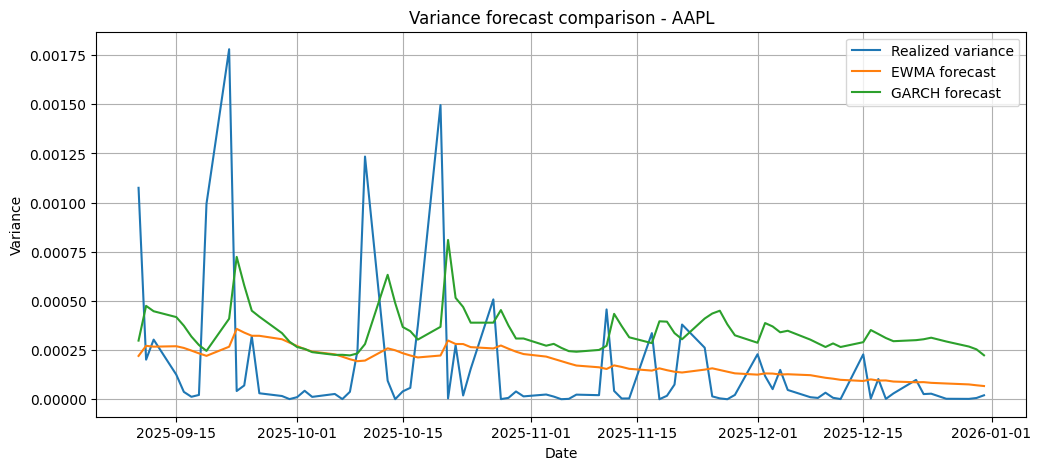

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(df_eval.index, df_eval["realized_var"], label="Realized variance")
plt.plot(df_eval.index, df_eval["ewma_var_pred"], label="EWMA forecast")
plt.plot(df_eval.index, df_eval["garch_var_pred"], label="GARCH forecast")
plt.title(f"Variance forecast comparison - {ticker}")
plt.xlabel("Date")
plt.ylabel("Variance")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
tickers_to_test = ["AAPL", "MSFT", "GGAL.BA", "YPFD.BA", "GLD", "SPY"]

summary_rows = []

for ticker in tickers_to_test:
    try:
        df_eval = evaluate_vol_models_for_ticker(
            returns_df=returns,
            ticker=ticker,
            train_window=252,
            test_horizon=80,
            ewma_lambda=0.94,
        )

        m_ewma = compute_metrics(df_eval, "ewma_var_pred")
        m_garch = compute_metrics(df_eval, "garch_var_pred")

        summary_rows.append({
            "ticker": ticker,
            "ewma_rmse": m_ewma["rmse"],
            "ewma_mae": m_ewma["mae"],
            "ewma_corr": m_ewma["corr"],
            "garch_rmse": m_garch["rmse"],
            "garch_mae": m_garch["mae"],
            "garch_corr": m_garch["corr"],
        })

    except Exception as e:
        print(f"{ticker}: ERROR -> {e}")

summary_df = pd.DataFrame(summary_rows)
summary_df

,ticker,ewma_rmse,ewma_mae,ewma_corr,garch_rmse,garch_mae,garch_corr
0,AAPL,0.000327,0.000210,0.157908,0.000396,0.000328,-0.010359
1,MSFT,0.000192,0.000137,0.015415,0.000231,0.000203,-0.112454
2,GGAL.BA,0.012273,0.004788,-0.027908,0.012476,0.004795,-0.067916
3,YPFD.BA,0.005648,0.002504,0.007746,0.005652,0.002308,-0.062132
4,GLD,0.000566,0.000250,0.042552,0.000567,0.000246,0.095007
5,SPY,0.000102,0.000054,-0.001982,0.000106,0.000068,0.067170


In [13]:
summary_df["winner_rmse"] = np.where(
    summary_df["garch_rmse"] < summary_df["ewma_rmse"],
    "GARCH",
    "EWMA"
)

summary_df["winner_corr"] = np.where(
    summary_df["garch_corr"] > summary_df["ewma_corr"],
    "GARCH",
    "EWMA"
)

summary_df

,ticker,ewma_rmse,ewma_mae,ewma_corr,garch_rmse,garch_mae,garch_corr,winner_rmse,winner_corr
0,AAPL,0.000327,0.000210,0.157908,0.000396,0.000328,-0.010359,EWMA,EWMA
1,MSFT,0.000192,0.000137,0.015415,0.000231,0.000203,-0.112454,EWMA,EWMA
2,GGAL.BA,0.012273,0.004788,-0.027908,0.012476,0.004795,-0.067916,EWMA,EWMA
3,YPFD.BA,0.005648,0.002504,0.007746,0.005652,0.002308,-0.062132,EWMA,EWMA
4,GLD,0.000566,0.000250,0.042552,0.000567,0.000246,0.095007,EWMA,GARCH
5,SPY,0.000102,0.000054,-0.001982,0.000106,0.000068,0.067170,EWMA,GARCH


Pruebas de modelos

In [14]:
from arch import arch_model
import numpy as np


def garch_model(series, model_type="garch", dist="t"):
    s = series.dropna().astype(float)

    if len(s) < 252:
        return np.nan

    if model_type == "garch":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="Garch",
            p=1,
            q=1,
            dist=dist,
        )

    elif model_type == "egarch":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="EGarch",
            p=1,
            q=1,
            dist=dist,
        )

    elif model_type == "gjr":
        model = arch_model(
            s * 100,
            mean="Zero",
            vol="GARCH",
            p=1,
            o=1,   # <- clave (asimetría)
            q=1,
            dist=dist,
        )

    else:
        raise ValueError("model_type inválido")

    res = model.fit(disp="off")

    forecast = res.forecast(horizon=1)
    var_100 = float(forecast.variance.values[-1, 0])

    return var_100 / 10000.0

In [15]:
def evaluate_models(series, train_window=252, horizon=80):
    results = []

    for i in range(len(series) - horizon - 1, len(series) - 1):

        train = series.iloc[i - train_window + 1 : i + 1]
        realized = float(series.iloc[i + 1] ** 2)

        row = {
            "realized": realized,
            "ewma": ewma_next_day_variance_forecast(train),
        }

        for model_name in ["garch", "egarch", "gjr"]:
            try:
                row[model_name] = garch_model(train, model_name)
            except:
                row[model_name] = np.nan

        results.append(row)

    return pd.DataFrame(results)

In [16]:
def compare_all_models(df):

    metrics = {}

    for col in ["ewma", "garch", "egarch", "gjr"]:
        tmp = df[["realized", col]].dropna()

        if len(tmp) == 0:
            continue

        err = tmp[col] - tmp["realized"]

        metrics[col] = {
            "rmse": np.sqrt(np.mean(err**2)),
            "mae": np.mean(np.abs(err)),
            "corr": tmp["realized"].corr(tmp[col]),
        }

    return pd.DataFrame(metrics).T

In [19]:
ticker = "AAPL"

series = returns[ticker].dropna()

df_test = evaluate_models(series)

compare_all_models(df_test)

,rmse,mae,corr
ewma,0.000327,0.000210,0.157908
garch,0.000396,0.000328,-0.010359
egarch,0.000416,0.000346,-0.011592
gjr,0.000352,0.000254,0.041508


In [20]:
returns[ticker].std()

np.float64(0.019134713526537124)

In [30]:
import numpy as np
import pandas as pd

def compute_asset_diagnostics(series: pd.Series):
    s = series.dropna().astype(float)

    if len(s) < 50:
        return None

    stats = {}

    # =========================
    # BASIC STATS
    # =========================
    stats["n_obs"] = len(s)
    stats["mean"] = s.mean()
    stats["std"] = s.std()
    stats["skew"] = s.skew()
    stats["kurtosis"] = s.kurtosis()

    # =========================
    # AUTOCORRELATION
    # =========================
    stats["acf_ret_1"] = s.autocorr(lag=1)
    stats["acf_ret_5"] = s.autocorr(lag=5)

    stats["acf_abs_1"] = s.abs().autocorr(lag=1)
    stats["acf_abs_5"] = s.abs().autocorr(lag=5)

    stats["acf_sq_1"] = (s**2).autocorr(lag=1)
    stats["acf_sq_5"] = (s**2).autocorr(lag=5)

    # =========================
    # VOL CLUSTERING (proxy)
    # =========================
    stats["vol_clustering"] = stats["acf_sq_1"]

    # =========================
    # TAIL RISK
    # =========================
    stats["p1"] = np.percentile(s, 1)
    stats["p5"] = np.percentile(s, 5)
    stats["p95"] = np.percentile(s, 95)
    stats["p99"] = np.percentile(s, 99)

    # =========================
    # VAR
    # =========================
    stats["VaR_95"] = stats["p5"]
    stats["VaR_99"] = stats["p1"]

    return stats

In [34]:
diagnostics = []

for ticker in returns.columns:
    try:
        stats = compute_asset_diagnostics(returns[ticker])

        if stats is None:
            continue

        stats["ticker"] = ticker
        diagnostics.append(stats)

    except Exception as e:
        diagnostics.append({
            "ticker": ticker,
            "error": str(e)
        })

diagnostics_df = pd.DataFrame(diagnostics)

diagnostics_df

,n_obs,mean,std,skew,kurtosis,acf_ret_1,acf_ret_5,acf_abs_1,acf_abs_5,acf_sq_1,acf_sq_5,vol_clustering,p1,p5,p95,p99,VaR_95,VaR_99,ticker
0,2061,0.000926,0.019135,-0.082395,6.453312,-0.068531,0.015817,0.238548,0.193139,0.280850,0.185280,0.280850,-0.050660,-0.030191,0.028689,0.049423,-0.030191,-0.050660,AAPL
1,2061,-0.000016,0.032395,-0.307514,3.193877,0.094561,0.027618,0.193389,0.139945,0.173951,0.154054,0.173951,-0.085849,-0.050726,0.051359,0.089706,-0.050726,-0.085849,ALUA.BA
2,2061,0.000658,0.021395,-0.103417,4.440076,-0.037162,-0.005394,0.182217,0.149083,0.160990,0.060561,0.160990,-0.057698,-0.032839,0.033777,0.059440,-0.032839,-0.057698,AMZN
3,2061,-0.000004,0.043605,-1.297632,27.783857,-0.011524,0.002945,0.077349,0.061427,0.016169,0.005316,0.016169,-0.098810,-0.062163,0.067381,0.107190,-0.062163,-0.098810,BBAR.BA
4,2061,0.000025,0.042940,-1.378999,27.587839,-0.015388,-0.002677,0.084219,0.051022,0.026369,0.005472,0.026369,-0.101511,-0.060902,0.062336,0.110543,-0.060902,-0.101511,BMA.BA
5,2061,0.000454,0.012922,-0.315721,11.035707,-0.110645,0.023027,0.329042,0.228933,0.488295,0.219204,0.488295,-0.036770,-0.018559,0.017627,0.035734,-0.018559,-0.036770,BRK-B
6,2061,-0.000003,0.040215,-1.693541,37.184570,0.055272,-0.017532,0.115626,0.073287,0.053194,0.008377,0.053194,-0.089344,-0.055482,0.059110,0.106517,-0.055482,-0.089344,CEPU.BA
7,2061,-0.000060,0.036101,-0.006303,9.409876,0.159768,-0.023386,0.149119,0.101402,0.141244,0.037343,0.141244,-0.090710,-0.051470,0.055376,0.094565,-0.051470,-0.090710,COME.BA
8,2061,-0.000236,0.042074,-1.558456,38.240812,0.067642,0.016438,0.184822,0.095915,0.058022,0.009558,0.058022,-0.102604,-0.059217,0.062222,0.117302,-0.059217,-0.102604,EDN.BA
9,2061,0.000152,0.013075,-0.797413,11.103665,-0.138916,0.044798,0.297771,0.209690,0.400144,0.220058,0.400144,-0.034524,-0.019664,0.018669,0.031805,-0.019664,-0.034524,EEM


In [32]:
diagnostics_df = diagnostics_df.set_index("ticker")

diagnostics_df.sort_values("vol_clustering", ascending=False).head(10)

,n_obs,mean,std,skew,kurtosis,acf_ret_1,acf_ret_5,acf_abs_1,acf_abs_5,acf_sq_1,acf_sq_5,vol_clustering,p1,p5,p95,p99,VaR_95,VaR_99
ticker,,,,,,,,,,,,,,,,,,
BRK-B,2061,0.000454,0.012922,-0.315721,11.035707,-0.110645,0.023027,0.329042,0.228933,0.488295,0.219204,0.488295,-0.036770,-0.018559,0.017627,0.035734,-0.018559,-0.036770
PEP,2061,0.000214,0.012979,-0.436828,18.107243,-0.172997,0.060322,0.320808,0.251238,0.487046,0.293765,0.487046,-0.032760,-0.019003,0.017102,0.034362,-0.019003,-0.032760
MSFT,2061,0.000879,0.017629,-0.161678,7.647703,-0.160270,0.016845,0.281747,0.227101,0.472988,0.180321,0.472988,-0.045072,-0.027458,0.025573,0.047041,-0.027458,-0.045072
TLT,2061,-0.000069,0.009794,0.064564,4.978354,-0.017721,0.049263,0.271969,0.220827,0.462629,0.285500,0.462629,-0.023684,-0.015627,0.015282,0.024520,-0.015627,-0.023684
JPM,2061,0.000637,0.018041,-0.084576,13.534898,-0.107607,0.076038,0.369903,0.289285,0.432720,0.298324,0.432720,-0.047941,-0.026718,0.024628,0.045843,-0.026718,-0.047941
SPY,2061,0.000512,0.012134,-0.578079,13.912400,-0.133838,0.046311,0.356230,0.321363,0.420458,0.282278,0.420458,-0.034572,-0.017898,0.016014,0.027821,-0.017898,-0.034572
EEM,2061,0.000152,0.013075,-0.797413,11.103665,-0.138916,0.044798,0.297771,0.209690,0.400144,0.220058,0.400144,-0.034524,-0.019664,0.018669,0.031805,-0.019664,-0.034524
QQQ,2061,0.000683,0.014985,-0.373650,7.243843,-0.125676,0.016800,0.261115,0.267956,0.364583,0.231190,0.364583,-0.041574,-0.024780,0.021837,0.035992,-0.024780,-0.041574
EFA,2061,0.000265,0.011232,-1.025226,15.797471,-0.097973,0.067324,0.316892,0.238790,0.324547,0.220939,0.324547,-0.029103,-0.016092,0.015014,0.026459,-0.016092,-0.029103


In [33]:
def classify_asset(row):
    if row["acf_sq_1"] > 0.15:
        return "GARCH-friendly"
    elif row["acf_sq_1"] > 0.05:
        return "Mixed"
    else:
        return "EWMA-friendly"

diagnostics_df["class"] = diagnostics_df.apply(classify_asset, axis=1)

diagnostics_df["class"].value_counts()

class
GARCH-friendly    22
Mixed             10
EWMA-friendly      8
Name: count, dtype: int64

In [35]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from arch import arch_model

# =========================
# FILTRAR PERIODO RECIENTE
# =========================
returns_recent = returns.loc["2022-01-01":].copy()
returns_recent.columns = returns_recent.columns.astype(str).str.strip()

print("Periodo:", returns_recent.index.min(), "→", returns_recent.index.max())
print("Tickers:", len(returns_recent.columns))


# =========================
# MODELOS
# =========================
def ewma_forecast(series, lam=0.94):
    x = series.dropna().values
    if len(x) < 2:
        return np.nan
    var = np.var(x, ddof=1)
    for r in x:
        var = lam * var + (1 - lam) * (r**2)
    return var


def garch_forecast(series, model_type="garch", dist="t"):
    s = series.dropna()
    if len(s) < 252:
        return np.nan

    if model_type == "garch":
        model = arch_model(s * 100, mean="Zero", vol="Garch", p=1, q=1, dist=dist)
    elif model_type == "egarch":
        model = arch_model(s * 100, mean="Zero", vol="EGARCH", p=1, q=1, dist=dist)
    elif model_type == "gjr":
        model = arch_model(s * 100, mean="Zero", vol="GARCH", p=1, o=1, q=1, dist=dist)
    else:
        return np.nan

    try:
        res = model.fit(disp="off")
        f = res.forecast(horizon=1)
        return float(f.variance.values[-1, 0]) / 10000.0
    except:
        return np.nan


# =========================
# EVALUACION
# =========================
def evaluate_ticker(series, train_window=252, test_horizon=60):
    s = series.dropna()
    if len(s) < train_window + test_horizon:
        return None

    rows = []
    start = len(s) - test_horizon - 1

    for i in range(start, len(s) - 1):
        train = s.iloc[i - train_window + 1 : i + 1]
        realized = float(s.iloc[i + 1] ** 2)

        row = {
            "realized": realized,
            "ewma": ewma_forecast(train),
            "garch": garch_forecast(train, "garch"),
            "egarch": garch_forecast(train, "egarch"),
            "gjr": garch_forecast(train, "gjr"),
        }

        rows.append(row)

    return pd.DataFrame(rows)


def metrics(df, col):
    tmp = df[["realized", col]].dropna()
    if len(tmp) == 0:
        return (np.nan, np.nan, np.nan)

    err = tmp[col] - tmp["realized"]

    rmse = np.sqrt(np.mean(err**2))
    mae = np.mean(np.abs(err))
    corr = tmp["realized"].corr(tmp[col])

    return (rmse, mae, corr)


# =========================
# LOOP GLOBAL
# =========================
results = []

for ticker in returns_recent.columns:
    print("→", ticker)

    try:
        df_eval = evaluate_ticker(returns_recent[ticker])

        if df_eval is None:
            continue

        ewma_rmse, ewma_mae, ewma_corr = metrics(df_eval, "ewma")
        garch_rmse, garch_mae, garch_corr = metrics(df_eval, "garch")
        egarch_rmse, egarch_mae, egarch_corr = metrics(df_eval, "egarch")
        gjr_rmse, gjr_mae, gjr_corr = metrics(df_eval, "gjr")

        results.append({
            "ticker": ticker,

            "ewma_corr": ewma_corr,
            "garch_corr": garch_corr,
            "egarch_corr": egarch_corr,
            "gjr_corr": gjr_corr,

            "ewma_rmse": ewma_rmse,
            "garch_rmse": garch_rmse,
            "egarch_rmse": egarch_rmse,
            "gjr_rmse": gjr_rmse,
        })

    except Exception as e:
        print("error:", ticker, e)


summary_recent = pd.DataFrame(results)

# =========================
# GANADORES
# =========================
def winner_corr(row):
    vals = {
        "EWMA": row["ewma_corr"],
        "GARCH": row["garch_corr"],
        "EGARCH": row["egarch_corr"],
        "GJR": row["gjr_corr"],
    }
    vals = {k: v for k, v in vals.items() if pd.notna(v)}
    if not vals:
        return None
    return max(vals, key=vals.get)


summary_recent["winner_corr"] = summary_recent.apply(winner_corr, axis=1)

print("\nGANADORES POR CORR:\n")
print(summary_recent["winner_corr"].value_counts())

summary_recent.sort_values("ewma_corr", ascending=False).head()

Periodo: 2022-01-03 00:00:00 → 2025-12-31 00:00:00
Tickers: 40
→ AAPL
→ ALUA.BA
→ AMZN
→ BBAR.BA
→ BMA.BA
→ BRK-B
→ CEPU.BA
→ COME.BA


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\luc

→ EDN.BA


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


→ EEM
→ EFA
→ GGAL.BA
→ GLD
→ GOOGL
→ HYG
→ IEF


...

c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\luc

→ TSLA
→ TXAR.BA
→ UNH
→ V
→ VALO.BA
→ VNQ
→ XOM
→ YPFD.BA


c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
c:\Users\lucas\anaconda3\envs\IIA_cuda_env\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(



GANADORES POR CORR:

winner_corr
GJR       25
EGARCH     9
EWMA       4
GARCH      2
Name: count, dtype: int64


,ticker,ewma_corr,garch_corr,egarch_corr,gjr_corr,ewma_rmse,garch_rmse,egarch_rmse,gjr_rmse,winner_corr
0,AAPL,0.186108,-0.040814,-0.039529,0.061599,0.000261,0.000358,0.000382,0.000300,EWMA
36,VALO.BA,0.086025,0.049799,-0.035015,0.227265,0.005546,0.005646,0.006100,0.005385,GJR
7,COME.BA,0.039592,-0.008440,-0.000000,-0.019989,0.012150,0.012178,inf,0.012105,EWMA
14,HYG,0.024996,0.199696,0.118543,0.367508,0.000007,0.000007,0.000008,0.000007,GJR
37,VNQ,0.012112,0.068946,0.067150,0.103094,0.000111,0.000119,0.000117,0.000122,GJR
